<a href="https://colab.research.google.com/github/peigemitchell-svg/Google-Colab/blob/main/PhDAI_733_Group_Project_%E2%80%93_Diabetes_Hospital_Readmission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Course Project: Predicting Hospital Readmission in Diabetes Patients
Group 4 Project Part 1

Course: Python Application for Data Analytics in AI PhDAI 733

This project uses the Diabetes 130-US Hospitals dataset to explore
factors related to hospital readmission among patients with diabetes and develop a machine-learning model to predict readmission risk.

Required libraries: pandas, numpy, matplotlib, seaborn, scikit-learn

This project examines hospital readmission among patients with diabetes. The goal is to determine whether demographic, clinical, and hospitalization information can be used to predict whether a patient will be readmitted. The Diabetes 130-US Hospitals dataset contains 101,766 hospital encounters and 50 variables. The dataset includes demographic information, hospital stay details, diagnoses, medications, laboratory tests, and previous healthcare utilization.
The original readmitted variable contains three outcomes: No, >30, and <30. For the initial ML model, these outcomes are converted into a binary variable, where 'No' is coded as 0 (not readmitted) and '>30' and '<30' are coded as 1 (readmitted).

Research Question: How effectively can an ML model predict hospital readmission among patients with diabetes using demographic, clinical, and hospitalization data?

In [ ]:
# Download and load the Diabetes 130-US Hospitals dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
zip_path = "diabetes_dataset.zip"
data_folder = "diabetes_data"

# Download dataset directly from the UCI Machine Learning Repository
urllib.request.urlretrieve(url, zip_path)

# Extract dataset files
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_folder)

# Load the primary dataset
csv_path = os.path.join(data_folder, "diabetic_data.csv")
Diabetes_df = pd.read_csv(csv_path)

# Verify successful loading
print("Dataset loaded successfully.")
print("Dataset shape:", Diabetes_df.shape)
Diabetes_df.head()

Dataset loaded successfully.
Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


Missing values by variable:
 encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride        

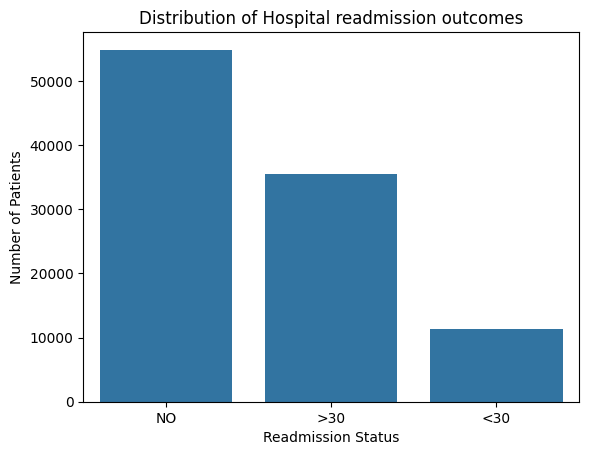

   N_readmission readmitted
0              0         NO
1              1        >30
2              0         NO
3              0         NO
4              0         NO
0
N_readmission
0    54864
1    46902
Name: count, dtype: int64


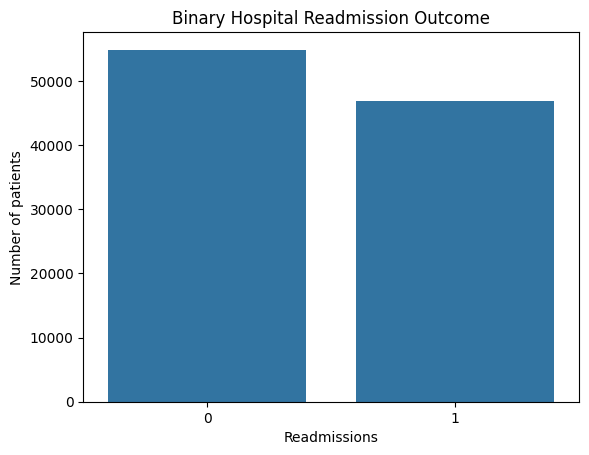

In [ ]:
#Replacing '?' with missing values
Diabetes_df = Diabetes_df.replace('?', pd.NA)
#Checking for missing values and duplicated records
print('Missing values by variable:\n', Diabetes_df.isnull().sum())
print('Number of duplicate records:', Diabetes_df.duplicated().sum())

#Summarizing missing values by variables
missing_summary = pd.DataFrame({'Missing Count': Diabetes_df.isnull().sum(), 'Missing Percentage': Diabetes_df.isnull().mean() *100})
print(missing_summary[missing_summary['Missing Count']>0].sort_values('Missing Percentage'))

#Replacing missing categorical values with 'Unknown'
categorical_missing = ['diag_1','diag_2','diag_3','race','payer_code','medical_specialty','A1Cresult','max_glu_serum']
for col in categorical_missing:
    Diabetes_df[col] = Diabetes_df[col].fillna('Unknown')

#Dropping weight as approximately 97% values are missing
Diabetes_df = Diabetes_df.drop(columns = ['weight'])

#Confirming there are no missing values in the dataset now
print((Diabetes_df.isnull().sum()).sum())


#Examining the original readmission outcomes
print(Diabetes_df['readmitted'].value_counts())
sns.countplot(data=Diabetes_df, x = 'readmitted')
plt.title('Distribution of Hospital readmission outcomes')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Patients')
plt.show()

#converting the three category readmission outcome into binary outcome (creating new N_readmission columns with 0 = Not readmitted and 1 = Readmitted)
Diabetes_df['N_readmission'] = Diabetes_df['readmitted'].map({'NO':0, '>30':1,
'<30':1})
#Printing the first five observations of the new column and readmitted column for reference
print(Diabetes_df[['N_readmission', 'readmitted']].head(5))
print(Diabetes_df['N_readmission'].isnull().sum())
#examining the new distribution
print(Diabetes_df['N_readmission'].value_counts())
sns.countplot(data=Diabetes_df, x = 'N_readmission')
plt.title ('Binary Hospital Readmission Outcome')
plt.xlabel('Readmissions')
plt.ylabel('Number of patients')
plt.show()

## Exploratory Data Analysis

In [ ]:
# Examine data types and available features
Diabetes_df.info()

# Summary of numerical variables
Diabetes_df.describe()

# Summary of categorical variables
Diabetes_df.describe(include='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   admission_type_id         101766 non-null  int64 
 6   discharge_disposition_id  101766 non-null  int64 
 7   admission_source_id       101766 non-null  int64 
 8   time_in_hospital          101766 non-null  int64 
 9   payer_code                101766 non-null  object
 10  medical_specialty         101766 non-null  object
 11  num_lab_procedures        101766 non-null  int64 
 12  num_procedures            101766 non-null  int64 
 13  num_medications           101766 non-null  int64 
 14  numb

,race,gender,age,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,A1Cresult,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,18,73,717,749,790,4,4,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),Unknown,Unknown,428,276,250,Unknown,Unknown,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,40256,49949,6862,6752,11555,96420,84748,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


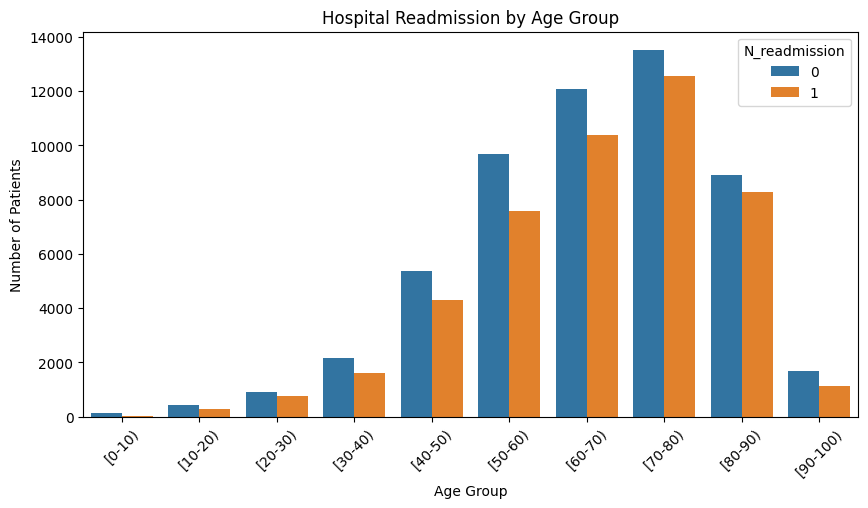

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=Diabetes_df, x='age', hue='N_readmission')
plt.title('Hospital Readmission by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.show()

### Exploratory Analysis of Readmission Patterns

Additional exploratory analysis was conducted to examine relationships between hospital readmission and selected demographic, clinical, and healthcare utilization variables. These comparisons help identify potentially informative predictors for subsequent model development.

In [ ]:
# Calculate readmission rate by age group
age_readmission = (
    Diabetes_df.groupby('age', observed=False)['N_readmission']
    .agg(['count', 'mean'])
    .reset_index()
)

age_readmission['Readmission Rate (%)'] = age_readmission['mean'] * 100

print(age_readmission[['age', 'count', 'Readmission Rate (%)']].to_string(index=False))

     age  count  Readmission Rate (%)
  [0-10)    161             18.012422
 [10-20)    691             38.205499
 [20-30)   1657             45.021123
 [30-40)   3775             42.675497
 [40-50)   9685             44.450181
 [50-60)  17256             43.955726
 [60-70)  22483             46.252724
 [70-80)  26068             48.120301
 [80-90)  17197             48.270047
[90-100)   2793             40.028643


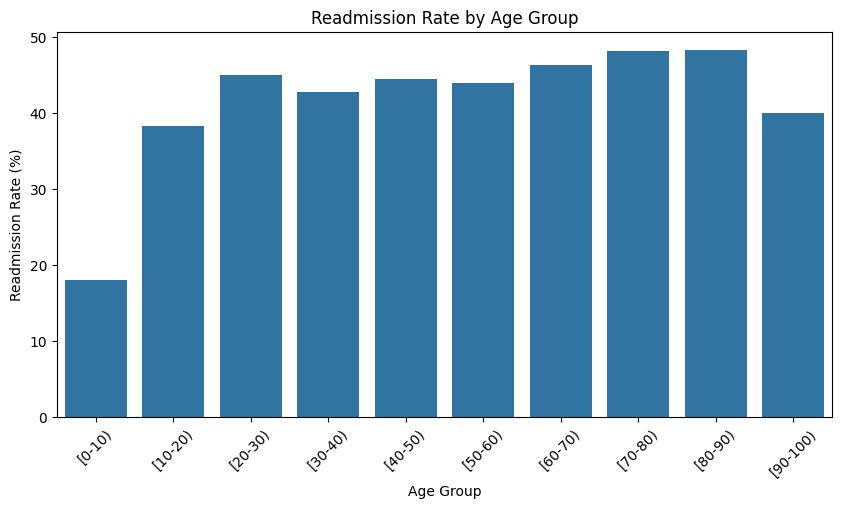

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_readmission,
    x='age',
    y='Readmission Rate (%)'
)

plt.title('Readmission Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=45)
plt.show()

#### Readmission by Age

Readmission rates varied across age groups, with a general increase among older patients. The lowest readmission rate occurred among patients ages 0–9 (18.0%), while rates were highest among patients ages 70–79 (48.1%) and 80–89 (48.3%). The rate declined to 40.0% among patients ages 90–99, indicating that the relationship between age and readmission was not strictly linear. These results suggest that age may provide useful predictive information for the initial classification model.

                   Not Readmitted  Readmitted
number_inpatient            0.382       0.932
number_emergency            0.109       0.302
number_outpatient           0.273       0.482


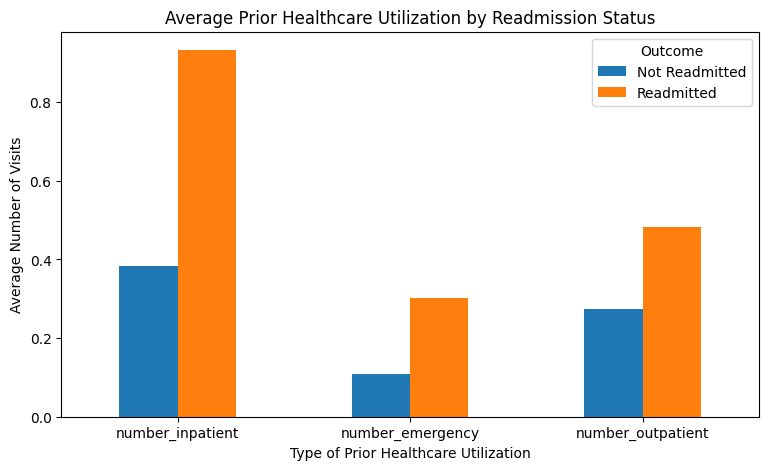

In [ ]:
# Compare prior healthcare utilization by readmission status
utilization_summary = (
    Diabetes_df.groupby('N_readmission')[
        ['number_inpatient', 'number_emergency', 'number_outpatient']
    ]
    .mean()
    .T
)

utilization_summary.columns = ['Not Readmitted', 'Readmitted']

print(utilization_summary.round(3))

# Visualize average prior healthcare utilization
utilization_summary.plot(kind='bar', figsize=(9, 5))

plt.title('Average Prior Healthcare Utilization by Readmission Status')
plt.xlabel('Type of Prior Healthcare Utilization')
plt.ylabel('Average Number of Visits')
plt.xticks(rotation=0)
plt.legend(title='Outcome')
plt.show()

#### Prior Healthcare Utilization

Prior healthcare utilization was consistently higher among patients who were readmitted. Readmitted patients averaged 0.93 prior inpatient visits, 0.30 emergency visits, and 0.48 outpatient visits, compared with 0.38, 0.11, and 0.27 visits, respectively, among patients who were not readmitted. The largest difference occurred in prior inpatient utilization. These patterns suggest that previous healthcare utilization may provide useful predictive information for the initial readmission model.

## Initial Model Development

Two supervised machine-learning models were developed to evaluate whether demographic, clinical, and hospitalization characteristics could be used to predict hospital readmission. Logistic Regression was selected as an interpretable baseline classification model, while Random Forest was used as an ensemble-based approach capable of modeling more complex relationships among predictors.

### Feature Engineering and Model Preprocessing

In [ ]:
print("Dataset shape:", Diabetes_df.shape)
print("\nColumns:")
print(Diabetes_df.columns.tolist())

print("\nTarget distribution:")
print(Diabetes_df["N_readmission"].value_counts())
print(Diabetes_df["N_readmission"].value_counts(normalize=True))

print("\nUnique patients:", Diabetes_df["patient_nbr"].nunique())
print("Unique encounters:", Diabetes_df["encounter_id"].nunique())

Dataset shape: (101766, 50)

Columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'N_readmission']

Target distribution:
N_readmission
0    54864
1    46902
Name: count, dtype: int64
N_readmission
0    0.539119
1    0.460881
Name: propo

In [ ]:
# Define variables that should not be used as predictors
exclude_cols = [
    "encounter_id",      # encounter identifier
    "patient_nbr",       # patient identifier
    "readmitted",        # original outcome used to create target
    "N_readmission"      # target variable
]

# Define continuous/count variables
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# All remaining predictors are treated as categorical
feature_cols = [
    col for col in Diabetes_df.columns
    if col not in exclude_cols
]

categorical_features = [
    col for col in feature_cols
    if col not in numeric_features
]

print("Total predictor variables:", len(feature_cols))
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Total predictor variables: 46
Numeric predictors: 8
Categorical predictors: 38

Numeric features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


### Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Get unique patient IDs
unique_patients = Diabetes_df["patient_nbr"].unique()

# Split patients into training and testing groups
train_patients, test_patients = train_test_split(
    unique_patients,
    test_size=0.20,
    random_state=42
)

# Create encounter-level training and testing datasets
train_df = Diabetes_df[
    Diabetes_df["patient_nbr"].isin(train_patients)
].copy()

test_df = Diabetes_df[
    Diabetes_df["patient_nbr"].isin(test_patients)
].copy()

# Verify that no patient appears in both datasets
patient_overlap = set(train_df["patient_nbr"]).intersection(
    set(test_df["patient_nbr"])
)

print("Training encounters:", len(train_df))
print("Testing encounters:", len(test_df))
print("Training patients:", train_df["patient_nbr"].nunique())
print("Testing patients:", test_df["patient_nbr"].nunique())
print("Patients appearing in both sets:", len(patient_overlap))

print("\nTraining target distribution:")
print(train_df["N_readmission"].value_counts(normalize=True))

print("\nTesting target distribution:")
print(test_df["N_readmission"].value_counts(normalize=True))

Training encounters: 81477
Testing encounters: 20289
Training patients: 57214
Testing patients: 14304
Patients appearing in both sets: 0

Training target distribution:
N_readmission
0    0.537072
1    0.462928
Name: proportion, dtype: float64

Testing target distribution:
N_readmission
0    0.547341
1    0.452659
Name: proportion, dtype: float64


In [ ]:
for i, col in enumerate(Diabetes_df.columns, 1):
    print(f"{i}. {col}")

1. encounter_id
2. patient_nbr
3. race
4. gender
5. age
6. admission_type_id
7. discharge_disposition_id
8. admission_source_id
9. time_in_hospital
10. payer_code
11. medical_specialty
12. num_lab_procedures
13. num_procedures
14. num_medications
15. number_outpatient
16. number_emergency
17. number_inpatient
18. diag_1
19. diag_2
20. diag_3
21. number_diagnoses
22. max_glu_serum
23. A1Cresult
24. metformin
25. repaglinide
26. nateglinide
27. chlorpropamide
28. glimepiride
29. acetohexamide
30. glipizide
31. glyburide
32. tolbutamide
33. pioglitazone
34. rosiglitazone
35. acarbose
36. miglitol
37. troglitazone
38. tolazamide
39. examide
40. citoglipton
41. insulin
42. glyburide-metformin
43. glipizide-metformin
44. glimepiride-pioglitazone
45. metformin-rosiglitazone
46. metformin-pioglitazone
47. change
48. diabetesMed
49. readmitted
50. N_readmission


In [ ]:
# Create predictor and target datasets from the patient-separated split
X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df["N_readmission"].copy()
y_test = test_df["N_readmission"].copy()

# Verify dimensions and confirm target leakage variables are excluded
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTarget leakage check:")
print("readmitted in predictors:", "readmitted" in X_train.columns)
print("N_readmission in predictors:", "N_readmission" in X_train.columns)
print("patient_nbr in predictors:", "patient_nbr" in X_train.columns)
print("encounter_id in predictors:", "encounter_id" in X_train.columns)

X_train shape: (81477, 46)
X_test shape: (20289, 46)
y_train shape: (81477,)
y_test shape: (20289,)

Target leakage check:
readmitted in predictors: False
N_readmission in predictors: False
patient_nbr in predictors: False
encounter_id in predictors: False


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocess numeric and categorical predictors
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit preprocessing only on training data to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to the test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# Confirm training and testing sets have identical feature dimensions
print(
    "Same number of processed features:",
    X_train_processed.shape[1] == X_test_processed.shape[1]
)

Processed training shape: (81477, 2411)
Processed testing shape: (20289, 2411)
Same number of processed features: True


### Model Training

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training complete.")

Random Forest training complete.


In [ ]:
# Logistic regression using the team's shared training data

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=2000, solver="lbfgs")
lr_model.fit(X_train_processed, y_train)

print("Logistic regression training complete.")

Logistic regression training complete.


### Model Evaluation

Model performance is evaluated using appropriate classification metrics, including accuracy, precision, recall, F1-score, and a confusion matrix.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate Random Forest predictions
rf_predictions = rf_model.predict(X_test_processed)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("Random Forest Performance")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest Performance
Accuracy:  0.6329
Precision: 0.6510
Recall:    0.4074
F1-score:  0.5012

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.82      0.71     11105
           1       0.65      0.41      0.50      9184

    accuracy                           0.63     20289
   macro avg       0.64      0.61      0.61     20289
weighted avg       0.64      0.63      0.62     20289

Confusion Matrix:
[[9099 2006]
 [5442 3742]]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr_pred = lr_model.predict(X_test_processed)
lr_prob = lr_model.predict_proba(X_test_processed)[:, 1]

print("Logistic regression: any recorded readmission")
print(classification_report(
    y_test, lr_pred,
    target_names=["No readmission", "Readmission"]
))
print("Confusion matrix (rows: actual 0, 1; columns: predicted 0, 1):")
print(confusion_matrix(y_test, lr_pred, labels=[0, 1]))
print(f"ROC AUC: {roc_auc_score(y_test, lr_prob):.3f}")

Logistic regression: any recorded readmission
                precision    recall  f1-score   support

No readmission       0.66      0.72      0.69     11105
   Readmission       0.62      0.54      0.58      9184

      accuracy                           0.64     20289
     macro avg       0.64      0.63      0.63     20289
  weighted avg       0.64      0.64      0.64     20289

Confusion matrix (rows: actual 0, 1; columns: predicted 0, 1):
[[8026 3079]
 [4188 4996]]
ROC AUC: 0.693


Logistic Regression Evaluation   
Evaluated on the held-out patient test set, logistic regression classified readmission encounters with 64% accuracy and an ROC AUC of 0.693. For positive readmissions, performance yielded 62% precision, 54% recall, and an F1 score of 0.58. In absolute counts, the classifier detected 4,996 readmission cases and missed 4,188. Compared with the Random Forest model, logistic regression identified more readmission encounters (4,996 versus 3,742), but also produced more false positives (3,079 versus 2,006).

### Random Forest Evaluation

The baseline Random Forest model achieved an accuracy of 63.29%, precision of 65.10%, recall of 40.74%, and an F1-score of 50.12% for predicting readmission. The confusion matrix showed that the model correctly identified 3,742 readmitted encounters but failed to identify 5,442 encounters that resulted in readmission. Although the model demonstrated moderate precision, its lower recall indicates that a substantial proportion of readmitted patients were classified as not readmitted. These findings suggest that overall accuracy alone is insufficient for evaluating performance in this healthcare classification problem and that additional model tuning may be needed to improve sensitivity to readmission.

### Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

# Small tuning grid to keep computation manageable
rf_param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 15],
    "min_samples_leaf": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        max_features="sqrt"
    ),
    param_grid=rf_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_processed, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best cross-validation F1-score:", round(rf_grid.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 50}
Best cross-validation F1-score: 0.465


In [ ]:
# Evaluate the best tuned Random Forest on the held-out test set
rf_tuned = rf_grid.best_estimator_
rf_tuned_predictions = rf_tuned.predict(X_test_processed)

tuned_accuracy = accuracy_score(y_test, rf_tuned_predictions)
tuned_precision = precision_score(y_test, rf_tuned_predictions)
tuned_recall = recall_score(y_test, rf_tuned_predictions)
tuned_f1 = f1_score(y_test, rf_tuned_predictions)

print("Tuned Random Forest Performance")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_predictions))

Tuned Random Forest Performance
Accuracy:  0.6329
Precision: 0.6510
Recall:    0.4074
F1-score:  0.5012

Confusion Matrix:
[[9099 2006]
 [5442 3742]]


### Hyperparameter Tuning Results

GridSearchCV was used with three-fold cross-validation to evaluate eight Random Forest parameter combinations. The search identified a maximum tree depth of 15, a minimum of 2 samples per leaf, and 50 estimators as the best-performing configuration, with a cross-validation F1-score of 0.4650. These parameters were identical to those used in the baseline Random Forest model. Consequently, evaluation on the held-out test set produced unchanged performance, with 63.29% accuracy, 65.10% precision, 40.74% recall, and an F1-score of 50.12%. The tuning results therefore did not improve test-set performance but supported the baseline parameter configuration within the tested search space.

## Ethical Considerations

The use of machine learning to predict hospital readmission raises important ethical considerations related to bias, fairness, privacy, and model interpretation. Model performance should be considered across demographic groups because patterns in historical healthcare data may reflect existing disparities in access to care and treatment. Predictions should support, rather than replace, clinical judgment. Patient information must also be protected, and model limitations should be clearly communicated before predictions are used in healthcare decision-making.

## Team Collaboration Process